In [1]:
import numpy as np 
from sklearn.datasets import make_blobs
import pandas as pd 
import matplotlib.pyplot as plt 

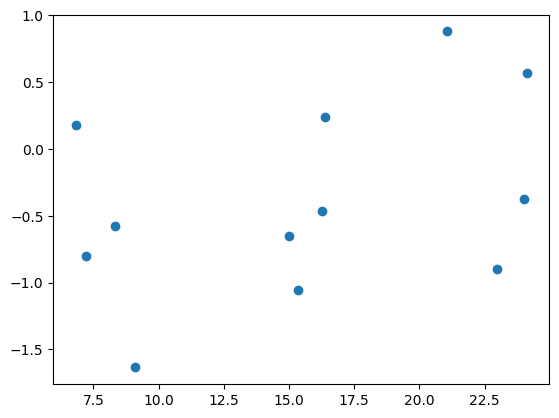

In [2]:
centroid_initial=[(8,0),(16,0),(23,0)]
x,y=make_blobs(n_samples=12,n_features=2,centers=centroid_initial)
plt.scatter(x[:,0],x[:,1])

In [3]:
class Kmeans:
    def __init__(self,n_clusters=2,max_iter=100):
        self.n_clusters=n_clusters
        self.max_iter=max_iter
        self.centroid=[(8,0),(16,0),(23,0)]

    def fit_predict(self,x):
        self.centroid=[(8,0),(16,0),(23,0)]  #initializing the cluster centroid 
        #now we will assign a point to centroids acc to thier distance  
         
        for i in range(self.max_iter):
            cluster_group=self.assign_cluster(x)    #will rep ki kis point ko konsa cluster mila 
            # we have to movethe centroid
            old_centroid=self.centroid
            self.centroid=self.move_centroids(x,cluster_group)

            #checking we have reached that final point or not 
            if (old_centroid==self.centroid).all():
                break
        return cluster_group


    def assign_cluster(self,x):
        cluster_group=[]
        #calculating the distance between points and centroid (no. of dist to be cal=12*3)
        distance=[]
        for row in x :
            for centroids in self.centroid:
                distance.append(np.sqrt(np.dot(row-centroids,row-centroids)))

            min_distance=min(distance)  #min distance of that point from all three centroid 
            index_pos=distance.index(min_distance)  #konse centroid se vo distance hai 
            cluster_group.append(index_pos)

            distance.clear()
        return np.array(cluster_group)
    

    def move_centroids(self,x,cluster_group):
        #ham har group ke points ka mean  calculate karenge vahi hamara new centroid hoga
        cluster_type=np.unique(cluster_group)
        new_centroid=[]
        for type in cluster_type:
            new_centroid.append(x[cluster_group==type].mean(axis=0)) #column wise mean aa jayega
        return np.array(new_centroid)

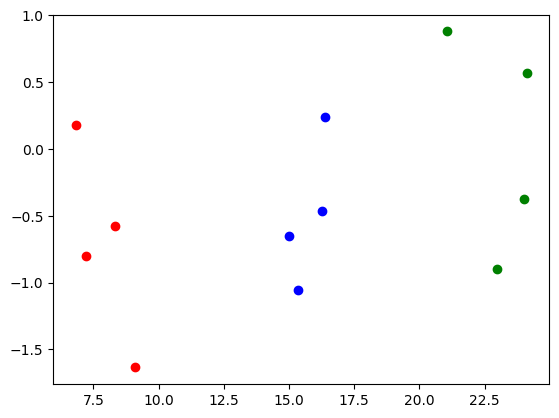

In [4]:
km=Kmeans()
y_means=km.fit_predict(x)
plt.scatter(x[y_means==0,0],x[y_means==0,1],color='red')
plt.scatter(x[y_means==1,0],x[y_means==1,1],color='blue')
plt.scatter(x[y_means==2,0],x[y_means==2,1],color='green')